# 计算复权价格

## 笔记：复权因子 adj_factor

### 是什么
- Tushare 接口 `pro.adj_factor()`，每只股票每天一个值
- 上市首日 = 1；每次除权除息乘一个比例，其余日子不变
- 除权日：因子_t = 因子_{t-1} × 前一天 close ÷ 当天 pre_close
- 例：昨收 10，派息 0.5，pre_close 调成 9.5 → 因子 × 10/9.5 ≈ × 1.053
- 中国平安 2024 年底因子 2.9955：上市以来分红送股累计，分红再投资后财富约为现价的 3 倍

### 三种价格

| 价格 | 公式 | 特点 |
|---|---|---|
| 未复权 Actual/Unadjusted Price | close | 和行情软件一致，除权日有假跳空 |
| 后复权 Backward Adjusted Price | close × 因子 | 历史价不变，最新价被放大（平安 52.65 → 157.7） |
| 前复权 Forward Adjusted Price | close × 因子 ÷ 最新因子 | 最新价是真实价，除权前的历史价被调低 |

### 前复权的例子
- 除权前一天：10 × f ÷ (f × 1.053) ≈ 9.5
- 除权日：9.5 × (f × 1.053) ÷ (f × 1.053) = 9.5
- 两天都是 9.5，收益率 0，假跳空消失

### 关键结论
- 前复权和后复权算出的**收益率完全相同**，只是价格刻度不同
- 项目里用后复权 `adj_close = close × adj_factor` 算收益
- 检验：除权日用 adj_close 算的收益 ≈ 当天 pct_chg / 100
- 注意：前复权依赖"最新因子"，以后有新分红，整段历史前复权价都会变；后复权的历史价不会变，所以回测用后复权更稳定

## 实操计算复权价格

In [1]:
import pandas as pd

daily = pd.read_csv('hs300_daily.csv', dtype={'trade_date': str}) #把日期转换成str类型，避免和tushare接口返回的str日期匹配不上
adj = pd.read_csv('hs300_adj.csv', dtype={'trade_date': str})
weights = pd.read_csv('hs300_weights.csv', dtype={'trade_date': str})

print(len(daily), len(adj))

693861 695906


In [2]:
adj.head()

,ts_code,trade_date,adj_factor
0,601318.SH,20241231,2.9955
1,601318.SH,20241230,2.9955
2,601318.SH,20241227,2.9955
3,601318.SH,20241226,2.9955
4,601318.SH,20241225,2.9955


In [3]:
daily.head()

,ts_code,trade_date,open,high,low,close,pre_close,change,pct_chg,vol,amount
0,601318.SH,20241231,53.79,54.02,52.65,52.65,53.90,-1.25,-2.3191,677117.90,3607846.474
1,601318.SH,20241230,53.22,53.90,53.21,53.90,53.27,0.63,1.1827,533437.83,2865180.504
2,601318.SH,20241227,53.45,53.75,52.71,53.27,53.45,-0.18,-0.3368,537757.19,2862446.917
3,601318.SH,20241226,53.89,53.94,53.36,53.45,53.90,-0.45,-0.8349,379221.70,2031175.519
4,601318.SH,20241225,53.81,54.31,53.57,53.90,53.78,0.12,0.2231,417398.96,2249897.990


In [4]:
extra = adj.merge(daily[['ts_code', 'trade_date']], on=['ts_code', 'trade_date'],
                  how='left', indicator=True)
extra.head()

#以复权因子为左表去匹配日线
#indicator=True:合并后多一列 _merge，标记每一行来自哪边：both 两边都有，left_only 只在左表有

,ts_code,trade_date,adj_factor,_merge
0,601318.SH,20241231,2.9955,both
1,601318.SH,20241230,2.9955,both
2,601318.SH,20241227,2.9955,both
3,601318.SH,20241226,2.9955,both
4,601318.SH,20241225,2.9955,both


In [5]:
print(extra[extra['_merge'] == 'left_only']['ts_code'].value_counts().head(10))

# == 'left_only'	筛出日线里没有的行
# value_counts()	统计每只股票出现几次，从多到少排列

ts_code
002450.SZ    432
000792.SZ    314
000413.SZ     94
002411.SZ     72
600816.SH     56
000671.SZ     46
000961.SZ     45
600518.SH     35
600297.SH     29
000425.SZ     23
Name: count, dtype: int64


**`可以得出结论，len(daily)<len(adj)是因为停牌的股票没有日线行，但是adj_factor即使停牌也会有`**

In [6]:
df = daily.merge(adj[['ts_code', 'trade_date', 'adj_factor']], #how这里选定daily不变，加上adj独有的列
                 on=['ts_code', 'trade_date'], how='left') #on...类似于vlookup的reference列

print('没有匹配到复权因子的行数:', df['adj_factor'].isna().sum())

df.head()

没有匹配到复权因子的行数: 0


,ts_code,trade_date,open,high,low,close,pre_close,change,pct_chg,vol,amount,adj_factor
0,601318.SH,20241231,53.79,54.02,52.65,52.65,53.90,-1.25,-2.3191,677117.90,3607846.474,2.9955
1,601318.SH,20241230,53.22,53.90,53.21,53.90,53.27,0.63,1.1827,533437.83,2865180.504,2.9955
2,601318.SH,20241227,53.45,53.75,52.71,53.27,53.45,-0.18,-0.3368,537757.19,2862446.917,2.9955
3,601318.SH,20241226,53.89,53.94,53.36,53.45,53.90,-0.45,-0.8349,379221.70,2031175.519,2.9955
4,601318.SH,20241225,53.81,54.31,53.57,53.90,53.78,0.12,0.2231,417398.96,2249897.990,2.9955


In [7]:
df['adj_close'] = df['close'] * df['adj_factor']

price = df.pivot(index='trade_date', columns='ts_code', values='adj_close').sort_index()
print(price.shape)

(1456, 499)


In [8]:
price.head()

ts_code,000001.SZ,000002.SZ,000063.SZ,000066.SZ,000069.SZ,000100.SZ,000157.SZ,000166.SZ,000301.SZ,000333.SZ,...,688256.SH,688271.SH,688303.SH,688363.SH,688396.SH,688472.SH,688506.SH,688561.SH,688599.SH,688981.SH
trade_date,,,,,,,,,,,,,,,,,,,,,
20190102,992.80489,3409.76520,308.79372,50.66547,231.42108,7.570662,236.88996,5.71256,11.96194,160.22668,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
20190103,1002.52768,3434.01876,296.47986,51.41846,231.80872,7.630986,240.30336,5.83982,11.80745,159.17140,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
20190104,1053.30225,3556.71324,303.11040,53.24715,237.62332,7.751634,243.03408,6.24988,11.89573,162.64503,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
20190107,1052.22194,3573.83340,316.05574,54.10771,239.94916,8.023092,246.44748,6.19332,11.96194,162.64503,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
20190108,1043.57946,3566.70000,314.16130,53.46229,237.23568,8.566008,247.81284,6.22160,11.80745,162.07342,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


# 调取各个因子以及基准指标

## 1. 估值指标：每个调仓日一次，取全市场

In [9]:
import tushare as ts
import time

pro = ts.pro_api()

rebal_dates = sorted(weights['trade_date'].unique()) #rebalance 就是"调仓日列表
codes = weights['con_code'].unique() #出现的股票代码列表

# 1. 估值指标：每个调仓日一次，取全市场
value_list = []
for d in rebal_dates:
    value_list.append(pro.daily_basic(trade_date=d, fields='ts_code,trade_date,pb,total_mv'))
    time.sleep(0.3)
valuation = pd.concat(value_list, ignore_index=True) #把前面的引索0,1...删掉
valuation.to_csv('valuation.csv', index=False) #只保留数据列，行号的引索列删掉
valuation.head()

,ts_code,trade_date,pb,total_mv
0,600230.SH,20190131,1.8311,6.635121e+05
1,600237.SH,20190131,1.4749,1.828557e+05
2,002465.SZ,20190131,2.1363,1.762505e+06
3,300732.SZ,20190131,2.2818,4.467966e+05
4,600007.SH,20190131,1.9861,1.337671e+06


## 2. 财务指标：每只股票一次

In [10]:
fina_list, failed = [], []
for i, code in enumerate(codes):
    try:
        fina_list.append(pro.fina_indicator(ts_code=code, start_date='20180101', end_date='20241231',
                                            fields='ts_code,ann_date,end_date,dt_eps,roe,debt_to_assets')) 
        #Announcement Date: 财报公布日，End date统计的哪个时间截止，比如第三季度，end_date是9月30号，ann_date可能是10月的某一天
    except Exception as e:
        failed.append(code)
        print(code, '失败:', e)
    time.sleep(0.3)
    if i % 50 == 0:
        print(f'进度 {i}/{len(codes)}')
fina = pd.concat(fina_list, ignore_index=True)
fina.to_csv('fina.csv', index=False)
fina.head()

进度 0/499
进度 50/499
进度 100/499
进度 150/499
进度 200/499
进度 250/499
进度 300/499
进度 350/499
进度 400/499
进度 450/499


,ts_code,ann_date,end_date,dt_eps,roe,debt_to_assets
0,601318.SH,20250320,20241231,6.99,13.8549,89.9311
1,601318.SH,20241022,20240930,6.58,13.1915,89.7908
2,601318.SH,20240823,20240630,4.12,8.1541,89.6542
3,601318.SH,20240424,20240331,2.03,4.0698,89.6335
4,601318.SH,20240424,20240331,NaN,4.0698,89.6335


## 3. 基准指数

In [11]:
# 3. 基准指数
bench = pro.index_daily(ts_code='000300.SH', start_date='20190101', end_date='20241231')
bench.to_csv('hs300_index.csv', index=False)
#index_daily() 调取的是某个指数指数本身的日线

bench.head()

,ts_code,trade_date,close,open,high,low,pre_close,change,pct_chg,vol,amount
0,000300.SH,20241231,3934.9109,3995.8705,4004.3462,3934.9109,3999.0549,-64.1440,-1.6040,183928397.0,3.478804e+08
1,000300.SH,20241230,3999.0549,3976.7004,4005.7780,3976.7004,3981.0307,18.0242,0.4528,164612485.0,3.226994e+08
2,000300.SH,20241227,3981.0307,3987.0189,4007.1314,3970.9365,3987.4801,-6.4494,-0.1617,169268666.0,3.450111e+08
3,000300.SH,20241226,3987.4801,3981.7317,3991.5331,3965.5461,3985.6291,1.8510,0.0464,143425286.0,3.057699e+08
4,000300.SH,20241225,3985.6291,3987.9557,4007.7626,3969.4766,3983.6882,1.9409,0.0487,159390747.0,2.992951e+08


In [12]:
print(valuation.shape, fina.shape, bench.shape)
print('失败:', failed)

(327955, 4) (24439, 6) (1456, 11)
失败: []


## 去重财务指标里的重复行

In [13]:
print('去重前:', len(fina))

fina['n_missing'] = fina[['dt_eps', 'roe', 'debt_to_assets']].isna().sum(axis=1) #添辅助列，axis=1 是横着数，每行得到一个数
fina = (fina.sort_values(['ts_code', 'end_date', 'ann_date', 'n_missing']) #按照列表里的指标的依次排序，默认是升序
            .drop_duplicates(subset=['ts_code', 'ann_date', 'end_date'], keep='first') #去除三个指标都相同的列，只保留出现的第一个，缺失的最少的
            .drop(columns='n_missing')) #最后去除辅助列

print('去重后:', len(fina))
fina.to_csv('fina.csv', index=False)
fina.head()

去重前: 24439
去重后: 13748


,ts_code,ann_date,end_date,dt_eps,roe,debt_to_assets
649,000001.SZ,20180420,20180331,0.33,2.9611,93.3088
647,000001.SZ,20180816,20180630,0.73,5.9405,93.2250
645,000001.SZ,20181024,20180930,1.14,8.9467,92.9825
643,000001.SZ,20190307,20181231,1.39,10.7415,92.9783
641,000001.SZ,20190424,20190331,0.36,3.0331,92.8916


In [14]:
fina = fina.reset_index(drop=True)
fina.head()

,ts_code,ann_date,end_date,dt_eps,roe,debt_to_assets
0,000001.SZ,20180420,20180331,0.33,2.9611,93.3088
1,000001.SZ,20180816,20180630,0.73,5.9405,93.2250
2,000001.SZ,20181024,20180930,1.14,8.9467,92.9825
3,000001.SZ,20190307,20181231,1.39,10.7415,92.9783
4,000001.SZ,20190424,20190331,0.36,3.0331,92.8916


In [15]:
print(fina.groupby('ts_code').size().describe())
print(fina[['dt_eps', 'roe', 'debt_to_assets']].isna().sum())

count    499.000000
mean      27.551102
std        1.594070
min       16.000000
25%       28.000000
50%       28.000000
75%       28.000000
max       29.000000
dtype: float64
dt_eps            780
roe                49
debt_to_assets    122
dtype: int64


## 判断一下缺失最多的dt_eps的分布（以便考虑换因子）

In [16]:

fina = pd.read_csv('fina.csv', dtype={'ann_date': str, 'end_date': str})

miss = fina[fina['dt_eps'].isna()]

print('缺失涉及的股票数:', miss['ts_code'].nunique())

print('\n按报告类型(月日):')
print(miss['end_date'].str[4:].value_counts()) #第五个字符开始和以后，也就是月-日，看的应该是哪个季度的财报缺失

print('\n按年份:')
print(miss['end_date'].str[:4].value_counts().sort_index()) #前四个字符，也就是年份，sort_index()按年份升序排列

print('\n缺失最多的股票:')
print(miss['ts_code'].value_counts().head(10))

缺失涉及的股票数: 110

按报告类型(月日):
end_date
0331    217
0930    205
0630    198
1231    160
Name: count, dtype: int64

按年份:
end_date
2018    204
2019    157
2020    135
2021    101
2022     69
2023     56
2024     58
Name: count, dtype: int64

缺失最多的股票:
ts_code
000553.SZ    28
600085.SH    28
600741.SH    28
600958.SH    28
601828.SH    28
603156.SH    28
600309.SH    27
600754.SH    27
600104.SH    26
600153.SH    25
Name: count, dtype: int64


## 数据清洗案例：稀释 EPS 缺失
- 现象：dt_eps 缺失 780 行（约 6%）
- 排查：按报告类型、年份分布均匀；按股票高度集中，110 只股票几乎每期都缺
- 原因：无可转债、期权等稀释性证券的公司，稀释 EPS 等于基本 EPS，数据源常不单独填写
- 处理：dt_eps 缺失时用基本 eps 补（eps_factor）。不直接删除，否则 22% 的股票被排除，且排除标准与股票好坏无关，造成偏差
- 验证：两者都有值时 83% 完全相等；不相等时差值中位数 0.01 元
- 附带发现：dt_eps 因含空值被识别为 object 类型，用 pd.to_numeric 统一转为 float64

In [17]:
import tushare as ts
import pandas as pd
import time

pro = ts.pro_api()
weights = pd.read_csv('hs300_weights.csv', dtype={'trade_date': str})
codes = weights['con_code'].unique()

fina_list, failed = [], []
for i, code in enumerate(codes):
    try:
        fina_list.append(pro.fina_indicator(ts_code=code, start_date='20180101', end_date='20241231',
                                            fields='ts_code,ann_date,end_date,eps,dt_eps,roe,debt_to_assets'))
    except Exception as e:
        failed.append(code)
        print(code, '失败:', e)
    time.sleep(0.3)
    if i % 50 == 0:
        print(f'进度 {i}/{len(codes)}')

fina = pd.concat(fina_list, ignore_index=True)

# 去重：同一份财报保留最完整的一条
cols = ['eps', 'dt_eps', 'roe', 'debt_to_assets']
fina['n_missing'] = fina[cols].isna().sum(axis=1)
fina = (fina.sort_values(['ts_code', 'end_date', 'ann_date', 'n_missing'])
            .drop_duplicates(subset=['ts_code', 'ann_date', 'end_date'], keep='first')
            .drop(columns='n_missing'))

# 稀释 EPS 缺失时用基本 EPS 补
fina['eps_factor'] = fina['dt_eps'].fillna(fina['eps'])

fina.to_csv('fina.csv', index=False)

print('行数:', len(fina))
print(fina[['eps', 'dt_eps', 'eps_factor', 'roe', 'debt_to_assets']].isna().sum())
print('两者都有时，相等的比例:', (fina['dt_eps'] == fina['eps']).mean())

进度 0/499
进度 50/499
进度 100/499
进度 150/499
进度 200/499
进度 250/499
进度 300/499
进度 350/499
进度 400/499
进度 450/499
行数: 13748
eps               202
dt_eps            780
eps_factor        202
roe                49
debt_to_assets    122
dtype: int64
两者都有时，相等的比例: 0.7869508292115217


In [18]:
both = fina.dropna(subset=['eps', 'dt_eps']) #只要指定的列有一个为空，就删掉这一行
diff = (both['eps'] - both['dt_eps']).abs()
print('相等比例:', (diff == 0).mean())
print(diff[diff > 0].describe())

相等比例: 0.834284392350401
count     2149.00
unique     557.00
top          0.01
freq       440.00
dtype: float64


In [19]:
cols = ['eps', 'dt_eps', 'eps_factor', 'roe', 'debt_to_assets']
print(fina[cols].dtypes)

fina[cols] = fina[cols].apply(pd.to_numeric, errors='coerce') #对每一列做数值转换。errors='coerce' 表示转不了的值变成空值，而不是报错
print(fina[cols].dtypes)

fina.to_csv('fina.csv', index=False)

both = fina.dropna(subset=['eps', 'dt_eps'])
diff = (both['eps'] - both['dt_eps']).abs()
print(diff[diff > 0].describe())

eps               float64
dt_eps             object
eps_factor         object
roe               float64
debt_to_assets    float64
dtype: object
eps               float64
dt_eps            float64
eps_factor        float64
roe               float64
debt_to_assets    float64
dtype: object
count    2149.000000
mean        0.026506
std         0.070809
min         0.000100
25%         0.003100
50%         0.010000
75%         0.020000
max         1.620000
dtype: float64


# 公告日对齐
**在公告日早于调仓日的所有财报里，取最新的那份**

## left（来源weights）和right（来源fina）对齐

In [20]:
import pandas as pd
import tushare as ts
import time

pro = ts.pro_api()

In [21]:
weights = pd.read_csv('hs300_weights.csv', dtype={'trade_date': str})
weights.head()

,index_code,con_code,trade_date,weight
0,000300.SH,601318.SH,20191231,6.715
1,000300.SH,600519.SH,20191231,4.312
2,000300.SH,600036.SH,20191231,2.812
3,000300.SH,000651.SZ,20191231,2.289
4,000300.SH,601166.SH,20191231,2.088


In [22]:
# 左表：每个调仓日的成分股(一个月一次，一年12次)
left = weights[['trade_date', 'con_code']].rename(columns={'con_code': 'ts_code'}) #把weights里的股票代码改成ts_code，方便和fina这个dataframe对齐
left['date'] = pd.to_datetime(left['trade_date']) #pd.to_datetime() 把字符串转换成日期格式，方便后续按时间排序
left = left.sort_values('date')
left.reset_index(drop=True, inplace=True)
left.head()


,trade_date,ts_code,date
0,20190131,300408.SZ,2019-01-31
1,20190131,600352.SH,2019-01-31
2,20190131,000661.SZ,2019-01-31
3,20190131,601901.SH,2019-01-31
4,20190131,601985.SH,2019-01-31


In [23]:
# 右表：财报，按公告日排序
fina = pd.read_csv('fina.csv', dtype={'ann_date':str, 'end_date':str}) #这里类型转换很重要，csv里是数字，pd.to_datetime读数字是另外一个种格式
right = fina.copy() #.copy() 复制一份fina，避免修改原来的数据
right['ann_dt'] = pd.to_datetime(right['ann_date'])
right = right.sort_values(['ann_dt', 'end_date'])  #merge_asof 要求两张表都按匹配的日期列排好序，否则报错

right = right.reset_index(drop=True)

right.head()


,ts_code,ann_date,end_date,eps,dt_eps,roe,debt_to_assets,eps_factor,ann_dt
0,600705.SH,20180410,20180331,0.0900,0.0900,3.3449,87.1996,0.0900,2018-04-10
1,603369.SH,20180410,20180331,0.4040,0.4040,9.2291,19.9428,0.4040,2018-04-10
2,000959.SZ,20180413,20180331,0.0954,0.0954,1.8842,72.5187,0.0954,2018-04-13
3,300014.SZ,20180413,20180331,0.0900,0.0900,2.3639,60.0175,0.0900,2018-04-13
4,603156.SH,20180414,20180331,1.8259,NaN,9.8498,14.6368,1.8259,2018-04-14


In [24]:
# 合并的动作
aligned = pd.merge_asof(left, right,            #merge_asof() 按时间对齐，左表的每一行匹配右表中最近的时间
                        left_on='date', right_on='ann_dt',  #按照最近的公告日：ann_dt匹配
                        by='ts_code',
                        direction='backward', #只往过去找，也就是公告日早于调仓日的。这一项保证了没有未来函数
                        allow_exact_matches=False) #公告日等于调仓日的不算。公司常在收盘后发财报，调仓日当天收盘时未必看得到，保守起见排除

aligned.head(10)

,trade_date,ts_code,date,ann_date,end_date,eps,dt_eps,roe,debt_to_assets,eps_factor,ann_dt
0,20190131,300408.SZ,2019-01-31,20181030,20180930,0.5400,0.5400,14.9255,17.1498,0.5400,2018-10-30
1,20190131,600352.SH,2019-01-31,20181031,20180930,0.9771,0.9771,17.4763,58.1444,0.9771,2018-10-31
2,20190131,000661.SZ,2019-01-31,20181020,20180930,4.9300,4.9300,17.5577,29.7348,4.9300,2018-10-20
3,20190131,601901.SH,2019-01-31,20181031,20180930,0.0600,0.0600,1.2067,74.9157,0.0600,2018-10-31
4,20190131,601985.SH,2019-01-31,20181026,20180930,0.2470,0.2470,8.5388,74.3148,0.2470,2018-10-26
5,20190131,601800.SH,2019-01-31,20181031,20180930,0.7400,0.7400,6.9548,76.2557,0.7400,2018-10-31
6,20190131,000895.SZ,2019-01-31,20181031,20180930,1.1069,1.1069,24.9369,34.4955,1.1069,2018-10-31
7,20190131,300015.SZ,2019-01-31,20181027,20180930,0.3803,0.3768,16.5639,39.8832,0.3768,2018-10-27
8,20190131,600383.SH,2019-01-31,20181030,20180930,1.1600,1.1600,12.4438,76.4722,1.1600,2018-10-30
9,20190131,600029.SH,2019-01-31,20181031,20180930,0.4000,0.4000,7.2110,68.0174,0.4000,2018-10-31


In [25]:
print(aligned.shape) #11 = 3+9-1（因为有共同的列ts_code)
print('没有匹配到财报的行数:', aligned['end_date'].isna().sum())


(21600, 11)
没有匹配到财报的行数: 0


## 年化ROE和EPS

In [26]:
print(aligned[aligned['trade_date'] == '20240430']['end_date'].value_counts())

end_date
20240331    173
20231231    100
20230930     27
Name: count, dtype: int64


In [27]:
print(aligned['end_date'].isna().sum())                 # 有多少行缺失
print(aligned[aligned['end_date'].isna()][['trade_date', 'ts_code']].head(10))   # 是哪些行
print(aligned.loc[aligned['end_date'].isna(), 'trade_date'].value_counts().sort_index().head())  # 集中在哪些日期

print(aligned.loc[aligned['end_date'].isna(), 'ts_code'].unique())   # 是不是只有这一只
print(fina[fina['ts_code'] == '002602.SZ'].shape)                    # 财务表里它有几行

0
Empty DataFrame
Columns: [trade_date, ts_code]
Index: []
Series([], Name: count, dtype: int64)
<ArrowStringArray>
[]
Length: 0, dtype: str
(28, 8)


In [28]:
aligned = aligned.dropna(subset=['end_date'])   # 剔除无财务数据的股票（仅 002602.SZ）
aligned['end_date'].isna().sum()

np.int64(0)

**意思是在4月30号这个交易日当天，最近的公告，财报截止日有3月底的，有去年12月底的，有去年第三季度9月底的**
- 按规定，年报最晚 4 月 30 日必须公布
- 但是有 27 只股票用的仍是 2023 年三季报，因为它们恰好在 4 月 30 日当天才发布年报和一季报。
- 是因为设置了 allow_exact_matches=False，当天公布的不算，所以退回到上一份。这是代码按设计在工作，不是错误。

**因为每个股票的最新的fina数据是可能是季报或者年报，会影响ROE或者EPS,所以要年化一下**

In [29]:
month = aligned['end_date'].str[4:6].astype(int)   # 03、06、09、12
aligned['roe_ann'] = aligned['roe'] * 12 / month
aligned['eps_ann'] = aligned['eps_factor'] * 12 / month
aligned.to_csv('aligned.csv', index=False)

print(aligned[aligned['trade_date'] == '20240430']
      .groupby('end_date')[['roe', 'roe_ann']].median()) #4月30号调仓日这一天，按照最近报告的截止日分组，看roe和roe_ann中位数

              roe    roe_ann
end_date                    
20230930  8.88820  11.850933
20231231  8.34645   8.346450
20240331  2.62240  10.489600


In [30]:
mix = aligned.groupby('trade_date')['end_date'].nunique() #统计每个调仓日用到了几种不同的报告期，trade_date是weigths.csv里面的调仓日，一年12个月的每个月底左右
print(mix[mix > 1]) #只显示超过一种日期

trade_date
20190228    2
20190329    2
20190430    3
20190731    2
20190830    2
20191031    2
20200228    2
20200331    2
20200430    3
20200529    2
20200630    2
20200731    3
20200831    2
20201030    2
20210226    2
20210331    2
20210430    3
20210730    2
20210831    2
20211029    2
20220331    2
20220429    3
20220729    2
20220831    2
20221031    2
20230331    2
20230428    3
20230731    2
20230831    2
20231031    2
20240229    2
20240329    2
20240430    3
20240731    2
20240830    2
20241031    2
Name: end_date, dtype: int64


## 笔记：财报口径问题-不同报告期不能直接比较

### 1. 累计值与年化
- A 股财报的 EPS、ROE 是**年初累计到报告期末**的数字：一季报 3 个月，半年报 6 个月，三季报 9 个月，年报 12 个月
- 例：中国平安 2024 年 ROE：一季报 4.07%，半年报 8.15%，三季报 13.19%，年报 13.85%
- 同一调仓日，不同公司可能用的是不同报告期 → 直接排名等于比较"谁的报告期更长"
- 资产负债率是时点比率，不受影响
- v0 处理：年化，`roe_ann = roe × 12 / 月数`（一季报 ×4，半年报 ×2，三季报 ×4/3，年报 ×1）

**年化的缺陷（20240430 调仓日，ROE 中位数）**

| 报告期 | 原始 | 年化后 |
|---|---|---|
| 2023 三季报 | 8.89 | 11.85 |
| 2023 年报 | 8.35 | 8.35 |
| 2024 一季报 | 2.62 | 10.49 |

- 年化后一季报、三季报仍高于年报，原因：
  1. **四季度利润偏低**：年底集中计提减值、坏账准备，费用、年终奖集中确认 → 年化假设四个季度均匀，会高估
  2. **三组不是同一批公司、同一年份**：早披露和晚披露的公司经营状况可能不同；一季报是 2024 年，年报是 2023 年
- 结论：年化只缩小差距，不能消除 → 写入缺陷清单
- v1 改进：TTM（最近四个单季相加）

### 2. 为什么某些调仓日会混用多个报告期

| 报告 | 法定披露期限 | 对应调仓日的混用情况 |
|---|---|---|
| 年报 | 次年 1/1 – 4/30 | 2、3 月：年报 + 上年三季报 |
| 一季报 | 4/1 – 4/30 | 4 月：三季报 + 年报 + 一季报（3 种） |
| 半年报 | 7/1 – 8/31 | 7、8 月：一季报 + 半年报 |
| 三季报 | 10/1 – 10/31 | 10 月：半年报 + 三季报 |

- 5、6、9、11、12 月不在窗口内，所有公司用同一期报告
- 2020 年 5、6 月也有混用：疫情期间部分公司获准推迟披露（待查证）
- 72 个调仓日中约一半存在混用 → 年化这一步影响一半的调仓
- 4/30 仍有 27 只用三季报：它们在 4/30 当天才发布年报和一季报，而 `allow_exact_matches=False` 排除了当天公告

# 股票池筛选和打分

## 1. 合并估值和行业数据

In [31]:
import tushare as ts
import pandas as pd

pro = ts.pro_api()

valuation = pd.read_csv('valuation.csv', dtype={'trade_date': str})
aligned = pd.read_csv('aligned.csv', dtype={'trade_date':str, 'ann_date':str, 'end_date':str})

df = aligned.merge(valuation, on=['trade_date', 'ts_code'], how='left')
print(df.shape)

basic = pd.concat([pro.stock_basic(list_status=s, fields='ts_code,name,industry') for s in ['L', 'D', 'P']], ignore_index=True) 
#拉取三列，股票代码，公司名，行业
#L: list正常上市, D: delist退市, P: pause停市
#pd.contat([],ignore_index=True)依旧是列表里的元素拼接，这个元素也可以是df
basic.to_csv('stock_basic.csv', index=False) #这里basic其实是拉个全历史的股票的三列

df = df.merge(basic, on='ts_code', how='left') #df多了两个basic带来的信息：name和industry，公司名和行业

df.head()

(21600, 15)


,trade_date,ts_code,date,ann_date,end_date,eps,dt_eps,roe,debt_to_assets,eps_factor,ann_dt,roe_ann,eps_ann,pb,total_mv,name,industry
0,20190131,300408.SZ,2019-01-31,20181030,20180930,0.5400,0.5400,14.9255,17.1498,0.5400,2018-10-30,19.900667,0.720000,4.4060,2.913252e+06,三环集团,元器件
1,20190131,600352.SH,2019-01-31,20181031,20180930,0.9771,0.9771,17.4763,58.1444,0.9771,2018-10-31,23.301733,1.302800,1.6589,3.224052e+06,浙江龙盛,染料涂料
2,20190131,000661.SZ,2019-01-31,20181020,20180930,4.9300,4.9300,17.5577,29.7348,4.9300,2018-10-20,23.410267,6.573333,6.1671,3.161877e+06,长春高新,生物制药
3,20190131,601901.SH,2019-01-31,20181031,20180930,0.0600,0.0600,1.2067,74.9157,0.0600,2018-10-31,1.608933,0.080000,1.3289,5.038046e+06,方正证券,证券
4,20190131,601985.SH,2019-01-31,20181026,20180930,0.2470,0.2470,8.5388,74.3148,0.2470,2018-10-26,11.385067,0.329333,1.8425,8.389767e+06,中国核电,新型电力


In [32]:
#统计下pb缺失和行业缺失
print(df.shape)
print('缺估值:', df['pb'].isna().sum(), '缺行业:', df['industry'].isna().sum())

#.drop_duplicates()每个股票留一行，统计股票的行业分布，每个行业多少支股票
df.drop_duplicates('ts_code')['industry'].value_counts().head(25)

(21600, 17)
缺估值: 30 缺行业: 363


industry
证券      36
电气设备    29
银行      28
元器件     22
半导体     22
医疗保健    17
软件服务    16
化学制药    13
生物制药    12
化工原料    12
建筑工程    11
中成药     11
全国地产    10
通信设备    10
汽车整车     9
家用电器     9
小金属      8
IT设备     8
白酒       8
汽车配件     8
航空       7
仓储物流     7
火力发电     6
石油开采     6
煤炭开采     6
Name: count, dtype: int64

In [33]:
# 筛出缺行业的行
miss_ind = df[df['industry'].isna()]
#行业信息缺失涉及哪些股票
print('行业信息缺失涉及股票数:', miss_ind['ts_code'].nunique())
print('-------------------------------------------------------------------------------------------')
#每只缺了几个调仓日,同时统计每只缺失调仓日的时间跨度
print(miss_ind.groupby('ts_code')['trade_date'].agg(['count', 'min', 'max']))
print('-------------------------------------------------------------------------------------------')
#缺失行业的股票在basic里面吗
print('这些股票代码在 basic 里吗:', miss_ind['ts_code']       # ① 取出这一列的 Series（每个缺失行的股票代码，可能重复）
                                .drop_duplicates()         # ② 去重，每个代码只留一个
                                .isin(basic['ts_code'])    # ③ 逐个判断：这个代码在 basic 的 ts_code 列里出现吗？
                                .tolist())                 # ④ 把布尔 Series 转成 Python list)
print('-------------------------------------------------------------------------------------------')
#pb信息缺失涉及哪些股票
print(df[df['pb'].isna()]['ts_code'].value_counts())

行业信息缺失涉及股票数: 11
-------------------------------------------------------------------------------------------
           count       min       max
ts_code                             
000413.SZ     17  20190131  20200529
000627.SZ     29  20190131  20210531
000671.SZ     29  20190131  20210531
000961.SZ     29  20190131  20210531
002411.SZ     17  20190131  20200529
002450.SZ      5  20190131  20190531
600068.SH     29  20190131  20210531
600297.SH     29  20190131  20210531
600705.SH     35  20190131  20211130
600837.SH     72  20190131  20241231
601989.SH     72  20190131  20241231
-------------------------------------------------------------------------------------------
这些股票代码在 basic 里吗: [True, True, True, True, True, True, True, True, True, True, True]
-------------------------------------------------------------------------------------------
ts_code
600816.SH    4
600340.SH    2
002024.SZ    2
000661.SZ    1
000538.SZ    1
300124.SZ    1
000503.SZ    1
002456.SZ    1
002450.SZ    1

In [34]:
print(basic[basic['ts_code'].isin(miss_ind['ts_code'].unique())][['ts_code', 'name']])

        ts_code      name
5596  601989.SH   中国重工(退)
5617  600837.SH   海通证券(退)
5637  600705.SH   中航产融(退)
5684  600297.SH   广汇汽车(退)
5725  600068.SH    葛洲坝(退)
5799  002450.SZ    康得退(退)
5804  002411.SZ    必康退(退)
5831  000961.SZ   ST中南(退)
5861  000671.SZ  ST阳光城(退)
5869  000627.SZ  *ST天茂(退)
5900  000413.SZ   ST旭电(退)


可以分享的经验：**已退市股票的行业信息缺失，导致3只金融股混入股票池；通过排查缺失值发现并手动修正**
- 剩余 8 只行业缺失的股票已按名称逐一核对，均为非金融，保留为空

In [35]:
manual = {
    '600837.SH': '证券',
    '600705.SH': '多元金融',
    '000627.SZ': '保险',
}
df['industry'] = df['industry'].fillna(df['ts_code'].map(manual))   #df['ts_code'].map(manual) 把每行的股票代码换成字典里对应的行业，字典里没有的变成空值


## 2. 筛选股票池

In [36]:
daily = pd.read_csv('hs300_daily.csv', dtype={'trade_date': str}, usecols=['ts_code', 'trade_date']) #usecols = :只读取需要的两列
daily['traded'] = True  #每一行增加一列，标记当天有交易
df = df.merge(daily, on=['ts_code', 'trade_date'], how='left')  #给df增加了’traded‘这样一个判断列
df['traded'] = df['traded'].fillna(False).astype(bool) #把 df['traded'] 这一列里的缺失值（NaN / None）全部替换成 False，而且要转换成布尔类型

fin = ['银行','证券', '保险', '多元金融']
cols = ['eps_ann', 'roe_ann', 'debt_to_assets', 'pb', 'total_mv']

pool = df[(~df['industry'].isin(fin)) & (df['traded']) & (df['pb'] > 0)].dropna(subset=cols).copy() 
# ~是条件取反的意思 #.dropna(subset=cols)以及把因子有缺失值的行都删掉


In [37]:
#汇报一下刚刚的动作
print('剔除金融:', df['industry'].isin(fin).sum())
print('调仓日停牌:', (~df['traded']).sum())
print('PB 非正:', (df['pb'] <= 0).sum())
print('-------------------------------------------------------------------------------------------')

#统计一下每个调仓日
pool.groupby('trade_date').size().describe()       
# ① 按交易日分组
# ② 每组多少行，对应多少支股票 → 得到 index=日期, values=行数的 Series
# ③ 对这个 Series 做描述性统计

剔除金融: 3959
调仓日停牌: 30
PB 非正: 0
-------------------------------------------------------------------------------------------


count     72.000000
mean     244.750000
std        7.139949
min      234.000000
25%      238.500000
50%      247.000000
75%      251.250000
max      254.000000
dtype: float64

In [38]:
df.head()

,trade_date,ts_code,date,ann_date,end_date,eps,dt_eps,roe,debt_to_assets,eps_factor,ann_dt,roe_ann,eps_ann,pb,total_mv,name,industry,traded
0,20190131,300408.SZ,2019-01-31,20181030,20180930,0.5400,0.5400,14.9255,17.1498,0.5400,2018-10-30,19.900667,0.720000,4.4060,2.913252e+06,三环集团,元器件,True
1,20190131,600352.SH,2019-01-31,20181031,20180930,0.9771,0.9771,17.4763,58.1444,0.9771,2018-10-31,23.301733,1.302800,1.6589,3.224052e+06,浙江龙盛,染料涂料,True
2,20190131,000661.SZ,2019-01-31,20181020,20180930,4.9300,4.9300,17.5577,29.7348,4.9300,2018-10-20,23.410267,6.573333,6.1671,3.161877e+06,长春高新,生物制药,True
3,20190131,601901.SH,2019-01-31,20181031,20180930,0.0600,0.0600,1.2067,74.9157,0.0600,2018-10-31,1.608933,0.080000,1.3289,5.038046e+06,方正证券,证券,True
4,20190131,601985.SH,2019-01-31,20181026,20180930,0.2470,0.2470,8.5388,74.3148,0.2470,2018-10-26,11.385067,0.329333,1.8425,8.389767e+06,中国核电,新型电力,True


## 3. 打分和选股

In [39]:
higher = ['eps_ann', 'roe_ann']
lower = ['debt_to_assets', 'pb', 'total_mv']

g = pool.groupby('trade_date') #groupby()以后，下面给g排序就是在每个调仓日组内排序

In [40]:
pool['score'] = (g[higher].rank(ascending=True).sum(axis=1) #这里也是在组内打分
                 + g[lower].rank(ascending=False).sum(axis=1))

picks = (pool.sort_values(['trade_date', 'score'], ascending=[True, False]) #按调仓日升序，按照打分降序
             .groupby('trade_date').head(10)) #这里是groupby().head(10) 是为了取每组前10个才groupby先

picks[['trade_date', 'ts_code', 'name', 'score']].to_csv('picks.csv', index=False)
pool.to_csv('pool.csv', index=False)


In [41]:
picks.reset_index(drop = True, inplace=True)

In [42]:
print(picks.groupby('trade_date').size().value_counts()) #每个组多大，一共多少组
print(picks[picks['trade_date'] == '20241231'][['ts_code', 'name', 'industry', 'score']])

10    72
Name: count, dtype: int64
       ts_code  name industry   score
710  000661.SZ  长春高新     生物制药  1054.0
711  688169.SH  石头科技     家用电器   950.0
712  000807.SZ  云铝股份        铝   948.0
713  300896.SZ   爱美客     医疗保健   925.0
714  000786.SZ  北新建材     其他建材   924.0
715  600426.SH  华鲁恒升     农药化肥   922.0
716  300316.SZ  晶盛机电     专用机械   919.0
717  000408.SZ  藏格矿业     农药化肥   918.0
718  300628.SZ  亿联网络     通信设备   913.0
719  002422.SZ  科伦药业     化学制药   889.0


- 所以选出来的是**盈利好、负债低、估值不贵**、在沪深 300 里市值偏小的公司。
- 用量化的说法，这个策略同时暴露在**质量、价值、小市值**三类风格上

In [43]:
print(picks['trade_date'].unique())

<ArrowStringArray>
['20190131', '20190228', '20190329', '20190430', '20190531', '20190628',
 '20190731', '20190830', '20190930', '20191031', '20191129', '20191231',
 '20200123', '20200228', '20200331', '20200430', '20200529', '20200630',
 '20200731', '20200831', '20200930', '20201030', '20201130', '20201231',
 '20210129', '20210226', '20210331', '20210430', '20210531', '20210630',
 '20210730', '20210831', '20210930', '20211029', '20211130', '20211231',
 '20220128', '20220228', '20220331', '20220429', '20220531', '20220630',
 '20220729', '20220831', '20220930', '20221031', '20221130', '20221230',
 '20230131', '20230228', '20230331', '20230428', '20230531', '20230630',
 '20230731', '20230831', '20230928', '20231031', '20231130', '20231229',
 '20240131', '20240229', '20240329', '20240430', '20240531', '20240628',
 '20240731', '20240830', '20240930', '20241031', '20241129', '20241231']
Length: 72, dtype: str


# 计算收益，画图对比

## 4. 准备价格、收益和基准

In [44]:
import pandas as pd

daily = pd.read_csv('hs300_daily.csv', dtype={'trade_date': str})
adj = pd.read_csv('hs300_adj.csv', dtype={'trade_date': str})
picks = pd.read_csv('picks.csv', dtype={'trade_date': str})
bench = pd.read_csv('hs300_index.csv', dtype={'trade_date': str})

In [45]:
df = daily.merge(adj[['ts_code', 'trade_date', 'adj_factor']],
                 on=['ts_code', 'trade_date'], how='left') #on...类似于vlookup的reference列 #how这里选定daily不变，加上adj独有的列

df['adj_close'] = df['close'] * df['adj_factor']

price = df.pivot(index='trade_date', columns='ts_code', values='adj_close').sort_index()

print(price.shape)

(1456, 499)


In [46]:
price.to_csv('price.csv') #1456是交易日的个数，499是从2019年到24年底，沪深300出现的股票数

In [47]:
price.head()

ts_code,000001.SZ,000002.SZ,000063.SZ,000066.SZ,000069.SZ,000100.SZ,000157.SZ,000166.SZ,000301.SZ,000333.SZ,...,688256.SH,688271.SH,688303.SH,688363.SH,688396.SH,688472.SH,688506.SH,688561.SH,688599.SH,688981.SH
trade_date,,,,,,,,,,,,,,,,,,,,,
20190102,992.80489,3409.76520,308.79372,50.66547,231.42108,7.570662,236.88996,5.71256,11.96194,160.22668,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
20190103,1002.52768,3434.01876,296.47986,51.41846,231.80872,7.630986,240.30336,5.83982,11.80745,159.17140,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
20190104,1053.30225,3556.71324,303.11040,53.24715,237.62332,7.751634,243.03408,6.24988,11.89573,162.64503,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
20190107,1052.22194,3573.83340,316.05574,54.10771,239.94916,8.023092,246.44748,6.19332,11.96194,162.64503,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
20190108,1043.57946,3566.70000,314.16130,53.46229,237.23568,8.566008,247.81284,6.22160,11.80745,162.07342,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [48]:
#计算沪深300个股的每日return
ret = price.ffill().pct_change() #ffill() forward fill, 向下填充：某天没有价格（停牌），就沿用上一个交易日的价格

#计算沪深300指数的每日return
bench = bench.set_index('trade_date').sort_index()
bench_ret = bench['close'].pct_change()

In [49]:
ret.head()

ts_code,000001.SZ,000002.SZ,000063.SZ,000066.SZ,000069.SZ,000100.SZ,000157.SZ,000166.SZ,000301.SZ,000333.SZ,...,688256.SH,688271.SH,688303.SH,688363.SH,688396.SH,688472.SH,688506.SH,688561.SH,688599.SH,688981.SH
trade_date,,,,,,,,,,,,,,,,,,,,,
20190102,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
20190103,0.009793,0.007113,-0.039877,0.014862,0.001675,0.007968,0.014409,0.022277,-0.012915,-0.006586,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
20190104,0.050647,0.035729,0.022364,0.035565,0.025084,0.015810,0.011364,0.070218,0.007477,0.021823,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
20190107,-0.001026,0.004813,0.042708,0.016162,0.009788,0.035019,0.014045,-0.009050,0.005566,0.000000,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
20190108,-0.008214,-0.001996,-0.005994,-0.011928,-0.011309,0.067669,0.005540,0.004566,-0.012915,-0.003514,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [50]:
print(price.shape, ret.shape, bench_ret.shape)

(1456, 499) (1456, 499) (1456,)


In [51]:
bench_ret.head() #只有一列，是series数据

trade_date
20190102         NaN
20190103   -0.001580
20190104    0.023958
20190107    0.006070
20190108   -0.002161
Name: close, dtype: float64

## 5. 构造每日持仓权重，计算策略收益

In [52]:
picks['w'] = 0.1
picks.head()

,trade_date,ts_code,name,score,w
0,20190131,002450.SZ,康得退(退),966.0,0.1
1,20190131,603156.SH,养元饮品,929.0,0.1
2,20190131,002294.SZ,信立泰,923.0,0.1
3,20190131,300251.SZ,光线传媒,922.0,0.1
4,20190131,600516.SH,方大炭素,921.0,0.1


In [53]:
w = picks.pivot_table(index='trade_date', columns='ts_code', values='w', fill_value=0) 
#weight的矩阵, fill_value = 0, 缺失单元格从NaN变成0

print(w.shape) #72*81, 调仓日有72个，picks里入选的股票一共有81个（每个调仓日选10个，但是可能有重复的）
w.head()

(72, 81)


ts_code,000408.SZ,000423.SZ,000538.SZ,000661.SZ,000733.SZ,000786.SZ,000807.SZ,000898.SZ,000961.SZ,000963.SZ,...,603338.SH,603369.SH,603517.SH,603833.SH,603858.SH,603882.SH,603986.SH,688169.SH,688303.SH,688363.SH
trade_date,,,,,,,,,,,,,,,,,,,,,
20190131,0.0,0.1,0.0,0.0,0.0,0.1,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.1,0.0,0.0,0.0,0.0,0.0
20190228,0.0,0.1,0.0,0.0,0.0,0.1,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.1,0.0,0.0,0.0,0.0,0.0
20190329,0.0,0.1,0.0,0.0,0.0,0.1,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.1,0.0,0.0,0.0,0.0,0.0
20190430,0.1,0.1,0.0,0.0,0.0,0.0,0.0,0.1,0.0,0.0,...,0.0,0.0,0.0,0.0,0.0,0.0,0.1,0.0,0.0,0.0
20190531,0.0,0.1,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.0,...,0.0,0.0,0.0,0.0,0.1,0.0,0.0,0.0,0.0,0.0


- 这里我出现的疑惑：**这里value已经填成了0.1，为啥还有会空值（0）呢？**
- 其实很简单：看**每个调仓日，只选了10个股票**，所以一排中，只会有10个股票的权重是0.1

In [54]:
w_daily = (w.reindex(index=price.index) #把行索引（日期）扩充并对齐到 price（每日行情数据）的日期上
            .ffill()                    #持仓在没有到下一个调仓日之前，是保持不变的
            .reindex(columns=price.columns, fill_value=0) #把列索引（股票代码）对齐到 price 里所有股票代码，从未被选中的股票赋值0
            .fillna(0))
#第二行扩充解释： 如果 1月1日 买了 A股票 0.1，下次调仓是 1月31日。那么从 1月2日 到 1月30日，我们每天都持有它。
#ffill 就会把 1月1日 的 0.1 原封不动地复制给这期间的每一天。
#结果： 这样，每一天都有对应的权重了，填补了第 1 步产生的 NaN。



print(w_daily.shape) #这里w_daily的行列都已经和price以及ret一样了
w_daily.head()

(1456, 499)


ts_code,000001.SZ,000002.SZ,000063.SZ,000066.SZ,000069.SZ,000100.SZ,000157.SZ,000166.SZ,000301.SZ,000333.SZ,...,688256.SH,688271.SH,688303.SH,688363.SH,688396.SH,688472.SH,688506.SH,688561.SH,688599.SH,688981.SH
trade_date,,,,,,,,,,,,,,,,,,,,,
20190102,0,0,0,0,0,0,0,0,0,0,...,0,0,0.0,0.0,0,0,0,0,0,0
20190103,0,0,0,0,0,0,0,0,0,0,...,0,0,0.0,0.0,0,0,0,0,0,0
20190104,0,0,0,0,0,0,0,0,0,0,...,0,0,0.0,0.0,0,0,0,0,0,0
20190107,0,0,0,0,0,0,0,0,0,0,...,0,0,0.0,0.0,0,0,0,0,0,0
20190108,0,0,0,0,0,0,0,0,0,0,...,0,0,0.0,0.0,0,0,0,0,0,0


一些疑问，就是怎么把ffill()的范围怎么控制呢，它会只把0.1传递给该调仓日对应的月份吗，万一一直往下传了好几个月怎么办

答： 在 Pandas 中，ffill() 其实是**傻瓜式**的，它本身没有任何“范围控制”或“时间限制”。

它不会知道“这个月结束了，我该停了”。它的逻辑极其简单：遇到 `NaN`，就把上面最近的一个非空值复制下来；一旦遇到下一个非空值，就立刻停止复制旧的，改为复制新的。

**为什么在你的代码里，它不会出错、也不会“一直传好几个月”呢** 原因如下：

**为什么它会自己“停下来”？**

关键在于你前面生成的矩阵 w。
在上一节 pivot_table 中，你用了 fill_value=0。
这意味着，对于每一个调仓日，哪怕某只股票没有被买入，它的值也是 0.0，而不是 `NaN`。

我们假设调仓日是 1月31日 和 3月31日（中间隔了2个月，没有调仓）：

**原始 w 矩阵：**

2019-01-31 (调仓日): A股票 = 0.1 (买入), B股票 = 0.0 (没买)

2019-03-31 (调仓日): A股票 = 0.0 (卖出), B股票 = 0.1 (买入)

**第 1 步 reindex(index=price.index) 扩充日期后：**

2019-01-31 (调仓日): A=0.1, B=0.0

2019-02-01 ~ 02-28 (普通日): A=`NaN`, B=`NaN`

2019-03-01 ~ 03-30 (普通日): A=`NaN`, B=`NaN`

2019-03-31 (调仓日): A=0.0, B=0.1

**第 2 步 .ffill() 开始执行（从上往下复制）：**

2019-02-01: A=0.1, B=0.0 (复制了1月31日的数据)

2019-02-02: A=0.1, B=0.0

...

2019-03-30: A=0.1, B=0.0 (只要中间没有新数据，就会一直复制)

2019-03-31: 遇到 A=0.0, B=0.1 (这是实实在在的数据，不是`NaN`！)，ffill 立即被“阻断”，丢弃旧的 0.1，从这天起开始向下复制 0.0 和 0.1。

**结论：** 因为每一个调仓日都有完整的 81 只股票的数据（即使没买也是0），所以 ffill 最多只会把数据传递到下一个调仓日的前一天。到了下一个调仓日，就会被新数据强行覆盖掉。

In [55]:
#策略收益计算
strategy_ret = (w_daily.shift(1) * ret).sum(axis=1) 
    #第一次调仓日20190131之前，所有的w_daily都是0诶
    #0131被选中，然后收益在0201才体现，所以是0131的weight对应0201当天的收益
    #调仓日收盘建仓，从下一个交易日开始赚收益
    #sum(axis=1),按照行来加，相当于加权平均

strategy_ret.head(30)

trade_date
20190102    0.000000
20190103    0.000000
20190104    0.000000
20190107    0.000000
20190108    0.000000
20190109    0.000000
20190110    0.000000
20190111    0.000000
20190114    0.000000
20190115    0.000000
20190116    0.000000
20190117    0.000000
20190118    0.000000
20190121    0.000000
20190122    0.000000
20190123    0.000000
20190124    0.000000
20190125    0.000000
20190128    0.000000
20190129    0.000000
20190130    0.000000
20190131    0.000000
20190201    0.034552
20190211    0.026586
20190212    0.012115
20190213    0.023042
20190214    0.012535
20190215   -0.009633
20190218    0.029399
20190219   -0.000306
dtype: float64

In [56]:
#start起始日期
start = picks['trade_date'].min() #20190131

#策略return和基准return都更新一下
strategy_ret = strategy_ret[strategy_ret.index > start]
bench_ret = bench_ret[bench_ret.index > start]

print(w_daily.loc[w_daily.index > start].sum(axis=1).describe())

count    1434.0
mean        1.0
std         0.0
min         1.0
25%         1.0
50%         1.0
75%         1.0
max         1.0
dtype: float64


## 6. 净值曲线

In [57]:
import matplotlib.pyplot as plt

nav = (1 + strategy_ret).cumprod() #cumprod()每一行是累乘前面行的结果
bench_nav = (1 + bench_ret).cumprod()

print('策略期末净值:', round(nav.iloc[-1], 3)) #保留三位小数
print('基准期末净值:', round(bench_nav.iloc[-1], 3)) 

策略期末净值: 0.987
基准期末净值: 1.229


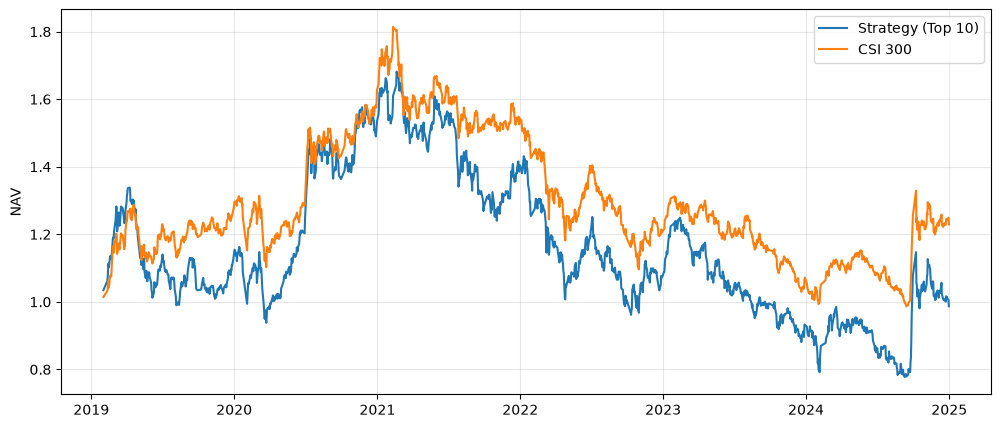

In [58]:
fig, ax = plt.subplots(figsize=(12, 5))
# fig 是整张画布。
# ax 是画布上的一个坐标系（一个子图）

ax.plot(pd.to_datetime(nav.index), nav.values, label='Strategy (Top 10)')
ax.plot(pd.to_datetime(bench_nav.index), bench_nav.values, label='CSI 300')
#to_datetime，转化成时间格式，作为横轴

ax.set_ylabel('NAV')
ax.legend() #加图例
ax.grid(alpha=0.3)
plt.show()

## 检验一：对照组，股票池全部等权持有

In [59]:
pool_w = pool[['trade_date', 'ts_code']].copy()
pool_w['w'] = 1 / pool_w.groupby('trade_date')['ts_code'].transform('count')
# groupby(...)['ts_code'].transform('count'),每个调仓日有多少只股票，结果填回每一行，用来算 1/N 的权重

w_pool = (pool_w.pivot_table(index='trade_date', columns='ts_code', values='w', fill_value=0)
                .reindex(index=price.index).ffill()
                .reindex(columns=price.columns, fill_value=0).fillna(0))

pool_ret = (w_pool.shift(1) * ret).sum(axis=1)
pool_ret = pool_ret[pool_ret.index > start]
pool_nav = (1 + pool_ret).cumprod()
print('股票池等权期末净值:', round(pool_nav.iloc[-1], 3))

股票池等权期末净值: 1.449


## 检验二：手算一期，和代码结果对比

In [60]:
p = picks[picks['trade_date'] == '20190131']['ts_code']
print(p)
manual = (price.loc['20190228', p] / price.loc['20190131', p] - 1).mean()
code = (1 + strategy_ret.loc['20190201':'20190228']).prod() - 1
print('手算:', round(manual, 4), '代码:', round(code, 4))

0    002450.SZ
1    603156.SH
2    002294.SZ
3    300251.SZ
4    600516.SH
5    000786.SZ
6    002925.SZ
7    603858.SH
8    000423.SZ
9    002001.SZ
Name: ts_code, dtype: str
手算: 0.2055 代码: 0.206


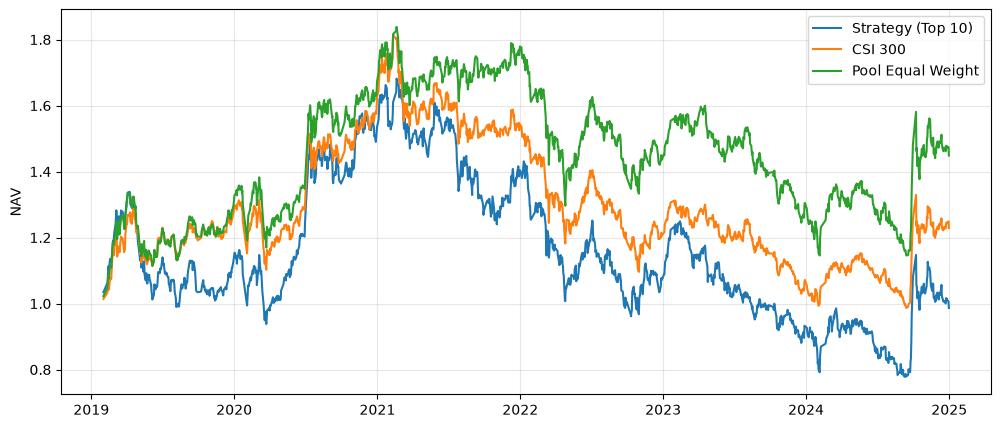

In [61]:
fig, ax = plt.subplots(figsize=(12, 5))

ax.plot(pd.to_datetime(nav.index), nav.values, label='Strategy (Top 10)')
ax.plot(pd.to_datetime(bench_nav.index), bench_nav.values, label='CSI 300')
ax.plot(pd.to_datetime(pool_nav.index), pool_nav.values, label='Pool Equal Weight')

ax.set_ylabel('NAV')
ax.legend()
ax.grid(alpha=0.3)
plt.show()

# 评价指标和IC

## 评价指标

In [62]:
import numpy as np

def perf(r):
    nav = (1 + r).cumprod()                         #这也是个series
    dates = pd.to_datetime(r.index)                 #日期是r的时间范围
    years = (dates[-1] - dates[0]).days / 365.25    #时间跨度是多少年
    per_year = len(r) / years                       #每年有多少交易日

    ann_ret = nav.iloc[-1] ** (1 / years) - 1       #年化收益
    ann_vol = r.std() * np.sqrt(per_year)           #年化收益的标准差，r.std()算的是每天的标准差，需要*每年交易日的平方根
    sharpe = ann_ret / ann_vol
    mdd = (nav / nav.cummax() - 1).min()            #max drawdown #每天距离历史最高点跌了多少，即回撤

    return pd.Series({'年化收益': ann_ret, '年化波动': ann_vol, '夏普比率': sharpe, '最大回撤': mdd}) 
        #返回一个series，index是键值，分别是年化收益、年化波动、夏普比率、最大回撤

table = pd.DataFrame({'策略': perf(strategy_ret),
                      '沪深300': perf(bench_ret),
                      '股票池等权': perf(pool_ret)})
print(table.round(4))  #把表里每个数字四舍五入保留 4 位小数


          策略   沪深300   股票池等权
年化收益 -0.0022  0.0355  0.0647
年化波动  0.2438  0.1933  0.2007
夏普比率 -0.0092  0.1836  0.3222
最大回撤 -0.5374 -0.4560 -0.3769


## IC计算实操

In [63]:
rebal = sorted(pool['trade_date'].unique())  #调仓日日期的列表
p_rb = price.ffill().loc[rebal]              #把price的调仓日的行挑出来 (price每一列是所有的交易日)
print(p_rb.shape)
p_rb.head()


(72, 499)


ts_code,000001.SZ,000002.SZ,000063.SZ,000066.SZ,000069.SZ,000100.SZ,000157.SZ,000166.SZ,000301.SZ,000333.SZ,...,688256.SH,688271.SH,688303.SH,688363.SH,688396.SH,688472.SH,688506.SH,688561.SH,688599.SH,688981.SH
trade_date,,,,,,,,,,,,,,,,,,,,,
20190131,1199.14410,3959.03700,317.47657,57.65752,248.08960,8.294550,253.95696,6.24988,10.72602,191.40141,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
20190228,1335.26316,3993.27732,470.45260,74.43844,268.24688,9.742326,286.72560,7.77700,11.91780,210.08866,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
20190329,1384.95742,4382.76096,460.98040,113.70149,298.48280,12.245772,305.84064,7.80528,13.24200,214.26581,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
20190430,1496.22935,4120.25184,507.55205,94.12375,308.17380,11.108896,337.92660,7.26796,13.13165,230.40280,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN
20190531,1315.81758,3809.23560,454.03412,105.20346,275.95084,10.242464,366.59916,6.74488,11.52054,223.84480,...,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN,NaN


In [64]:
fwd = (p_rb.shift(-1) / p_rb - 1).stack().rename('fwd_ret').reset_index()
        #.stack()宽表变长表：每行是"一个日期、一只股票、一个收益"
        #.reset_index()	把日期和股票代码从索引变回普通列，才能和 pool 合并,现在的index是ts_code以及trade_date，沿袭price
        # .shift(-1)每一行拿到的是未来的值
        # 之前的.shift(1)，每一行拿到的是过去的值
        # 因为我们算的是 在每个调仓日，因子值的排名和!!下一期收益!!的排名有多相关
        # 给这列计算的数据起名'fwd_ret'
print(fwd.shape)
fwd.head()

(35928, 3)


,trade_date,ts_code,fwd_ret
0,20190131,000001.SZ,0.113514
1,20190131,000002.SZ,0.008649
2,20190131,000063.SZ,0.481850
3,20190131,000066.SZ,0.291045
4,20190131,000069.SZ,0.081250


In [65]:
pool.head()

,trade_date,ts_code,date,ann_date,end_date,eps,dt_eps,roe,debt_to_assets,eps_factor,ann_dt,roe_ann,eps_ann,pb,total_mv,name,industry,traded,score
0,20190131,300408.SZ,2019-01-31,20181030,20180930,0.5400,0.5400,14.9255,17.1498,0.5400,2018-10-30,19.900667,0.720000,4.4060,2.913252e+06,三环集团,元器件,True,725.0
1,20190131,600352.SH,2019-01-31,20181031,20180930,0.9771,0.9771,17.4763,58.1444,0.9771,2018-10-31,23.301733,1.302800,1.6589,3.224052e+06,浙江龙盛,染料涂料,True,763.0
2,20190131,000661.SZ,2019-01-31,20181020,20180930,4.9300,4.9300,17.5577,29.7348,4.9300,2018-10-20,23.410267,6.573333,6.1671,3.161877e+06,长春高新,生物制药,True,808.0
4,20190131,601985.SH,2019-01-31,20181026,20180930,0.2470,0.2470,8.5388,74.3148,0.2470,2018-10-26,11.385067,0.329333,1.8425,8.389767e+06,中国核电,新型电力,True,381.0
5,20190131,601800.SH,2019-01-31,20181031,20180930,0.7400,0.7400,6.9548,76.2557,0.7400,2018-10-31,9.273067,0.986667,1.0164,1.719374e+07,中国交建,建筑工程,True,482.5


In [66]:


data = pool.merge(fwd, on=['trade_date', 'ts_code'], how='left').dropna(subset=['fwd_ret']) #把fwd_ret是缺失值的行删掉（最后一行没有下一期）

factors = ['score', 'eps_ann', 'roe_ann', 'debt_to_assets', 'pb', 'total_mv']
ic = data.groupby('trade_date').apply(
        lambda x: x[factors].corrwith(x['fwd_ret'], method='spearman')) 
        #corrwith(..., method='spearman')每个因子列分别和下期收益算相关系数，'spearman'是算Rank IC


In [67]:
print(ic.shape)
print(ic.dtypes)
ic.index.dtype
ic.head()

(71, 6)
score             float64
eps_ann           float64
roe_ann           float64
debt_to_assets    float64
pb                float64
total_mv          float64
dtype: object


,score,eps_ann,roe_ann,debt_to_assets,pb,total_mv
trade_date,,,,,,
20190131,0.031455,-0.242115,-0.107890,-0.117304,0.113817,-0.397137
20190228,0.121670,0.119277,0.109417,-0.073171,0.182408,-0.158292
20190329,0.000053,0.130890,0.063905,0.027849,-0.069900,0.300100
20190430,-0.012138,0.023463,0.033653,-0.045847,0.066189,0.070564
20190531,0.184773,0.319036,0.296969,-0.108459,0.116507,0.227967


In [68]:
summary = pd.DataFrame({'IC均值': ic.mean(),
                        'IC标准差': ic.std(),
                        'ICIR': ic.mean() / ic.std(),
                        'IC为正的比例': (ic > 0).mean()})
print(summary.round(3))

                 IC均值  IC标准差   ICIR  IC为正的比例
score          -0.003  0.109 -0.026    0.521
eps_ann        -0.009  0.139 -0.068    0.507
roe_ann        -0.002  0.158 -0.010    0.549
debt_to_assets -0.011  0.153 -0.075    0.507
pb             -0.011  0.258 -0.042    0.493
total_mv        0.017  0.182  0.093    0.549


## IC计算理解笔记：横截面 → 时间序列

### 第一层：groupby('trade_date') 按日期切开
- `data` 是长表：71 个调仓日 × 每天约 245 只股票 ≈ 17000 行
- 分组后变成 71 小块，每块 = 某一天的约 245 只股票（因子值 + 下期收益 fwd_ret）

### 第二层：每块里，每个因子算出一个数
- `lambda x:` 中的 `x` = 当前这一天的那一块
- 以 PB 为例：
  1. 245 只股票的 PB 排名 → 1 到 245
  2. 245 只股票的下期收益排名 → 1 到 245
  3. 两列**排名**的相关系数 → 一个数 = 这一天 PB 的 Rank IC
- `x[factors].corrwith(x['fwd_ret'], method='spearman')`：六个因子各算一遍 → 每天 6 个数

### 第三层：所有日期拼成 ic 表
- 形状 (71, 6)：行 = 调仓日，列 = 因子
- 每一格 = "某一天、某个因子"的 IC

| trade_date | score | eps_ann | roe_ann | debt_to_assets | pb | total_mv |
|---|---|---|---|---|---|---|
| 20190131 | … | … | … | … | … | … |
| 20190228 | … | … | … | … | … | … |

### 第四层：summary 按列汇总
- 对 ic 表每一列**往下**求均值、标准差 → 每个因子一个 IC 均值、一个 ICIR
- ICIR: Information Coefficient Information Ratio

### 小结
- **横截面**（同一天、不同股票）→ 相关系数 → 一天的 IC
- **时间序列**（不同天）→ 均值、标准差 → IC 均值、ICIR
- 为什么是 71 天不是 72 天：最后一个调仓日没有下一期收益，被 dropna 删掉

# 分组回测

## 1. 每个调仓日按 score 分五组

In [69]:
pool = pd.read_csv('pool.csv', dtype={'trade_date': str}) #dtype很重要！
n_groups = 5

pool.groupby('trade_date')['score'].transform(lambda s: print(type(s), len(s), s.name) or s)
    #跑跑看s拿的是什么数据，其实是每一日的二百多只股票的score的series
    #groupby 之后，每一块 Series 的 .name 会被 pandas 设成这一组的分组键，也就是调仓日字符串
    #print(...) or s 是函数里的一种防御性写法，不用太关系你这个

pool['group'] = (                           #增加新的列，是组号
    pool.groupby('trade_date')['score']
    .transform(lambda s: pd.qcut(s.rank(method='first'), n_groups, labels=False) + 1)
    )
    #pd.qcut(s.rank(method =''), 数字，labels=)，按分位数切成 5 个大小相等的箱，返回 0–4
    #.rank(method='first')：score 是排名相加得到的，会有大量并列值
    #qcut 遇到并列值可能报 Bin edges must be unique，或者切出大小不均的组。
    #method='first' 按出现顺序把并列拆开，保证每组人数一样
    #label=False,默认编码从0,1,2...，也可以指定比如：labels=[1,2,3,4,5]
    #lamda后面再+1转化成1-5
    #最外面的括号的意义是可以自由换行

pool.head()


<class 'pandas.Series'> 243 20190131
<class 'pandas.Series'> 241 20190228
<class 'pandas.Series'> 241 20190329
<class 'pandas.Series'> 241 20190430
<class 'pandas.Series'> 243 20190531
<class 'pandas.Series'> 240 20190628
<class 'pandas.Series'> 239 20190731
<class 'pandas.Series'> 240 20190830
<class 'pandas.Series'> 240 20190930
<class 'pandas.Series'> 240 20191031
<class 'pandas.Series'> 239 20191129
<class 'pandas.Series'> 236 20191231
<class 'pandas.Series'> 237 20200123
<class 'pandas.Series'> 237 20200228
<class 'pandas.Series'> 237 20200331
<class 'pandas.Series'> 237 20200430
<class 'pandas.Series'> 237 20200529
<class 'pandas.Series'> 236 20200630
<class 'pandas.Series'> 235 20200731
<class 'pandas.Series'> 236 20200831
<class 'pandas.Series'> 235 20200930
<class 'pandas.Series'> 236 20201030
<class 'pandas.Series'> 236 20201130
<class 'pandas.Series'> 235 20201231
<class 'pandas.Series'> 234 20210129
<class 'pandas.Series'> 234 20210226
<class 'pandas.Series'> 234 20210331
<

,trade_date,ts_code,date,ann_date,end_date,eps,dt_eps,roe,debt_to_assets,eps_factor,ann_dt,roe_ann,eps_ann,pb,total_mv,name,industry,traded,score,group
0,20190131,300408.SZ,2019-01-31,20181030,20180930,0.5400,0.5400,14.9255,17.1498,0.5400,2018-10-30,19.900667,0.720000,4.4060,2.913252e+06,三环集团,元器件,True,725.0,4
1,20190131,600352.SH,2019-01-31,20181031,20180930,0.9771,0.9771,17.4763,58.1444,0.9771,2018-10-31,23.301733,1.302800,1.6589,3.224052e+06,浙江龙盛,染料涂料,True,763.0,5
2,20190131,000661.SZ,2019-01-31,20181020,20180930,4.9300,4.9300,17.5577,29.7348,4.9300,2018-10-20,23.410267,6.573333,6.1671,3.161877e+06,长春高新,生物制药,True,808.0,5
3,20190131,601985.SH,2019-01-31,20181026,20180930,0.2470,0.2470,8.5388,74.3148,0.2470,2018-10-26,11.385067,0.329333,1.8425,8.389767e+06,中国核电,新型电力,True,381.0,1
4,20190131,601800.SH,2019-01-31,20181031,20180930,0.7400,0.7400,6.9548,76.2557,0.7400,2018-10-31,9.273067,0.986667,1.0164,1.719374e+07,中国交建,建筑工程,True,482.5,1


In [70]:
pool.groupby('trade_date').size().describe()

count     72.000000
mean     244.750000
std        7.139949
min      234.000000
25%      238.500000
50%      247.000000
75%      251.250000
max      254.000000
dtype: float64

In [71]:
print(pool.groupby(['trade_date', 'group']).size().unstack().agg(['min', 'max']))
#pool.groupby(['trade_date', 'group']).size() 得到的是一个长条 Series，有两层索引（MultiIndex）

#不加.unstack() 的话：.agg(['min','max']) 是对 360 个数一起算，只得到两个数，也就是全局最小和全局最大
#加了.unstack()，agg 默认按列算，得到一个 2 行 × 5 列的表





#预测是每组大约250/5 = 50个，大约有72*5=360个组
#min和max可能不相等，因为
#1. 每个调仓日剔除金融股之后，剩下的股票数量可能不太一样
#2. 同一个调仓日之内：比如 247 不能被 5 整除，qcut 只能切成 50/50/49/49/49 这样的组合
# 所以同一天的五组之间也有可能会差 1 只

group   1   2   3   4   5
min    47  47  46  47  47
max    51  51  51  51  51


In [72]:
print(pool.groupby(['trade_date', 'group']).size())

trade_date  group
20190131    1        49
            2        48
            3        49
            4        48
            5        49
                     ..
20241231    1        50
            2        50
            3        49
            4        50
            5        50
Length: 360, dtype: int64


In [73]:
print(pool.groupby(['trade_date', 'group']).size().unstack())
#.unstack() 把最内层索引（group）转成列，变成 72 行 × 5 列的宽表

group        1   2   3   4   5
trade_date                    
20190131    49  48  49  48  49
20190228    49  48  48  48  48
20190329    49  48  48  48  48
20190430    49  48  48  48  48
20190531    49  48  49  48  49
...         ..  ..  ..  ..  ..
20240830    51  50  50  50  50
20240930    51  50  50  50  50
20241031    51  50  50  50  50
20241129    51  50  50  50  50
20241231    50  50  49  50  50

[72 rows x 5 columns]


In [74]:
print(pool.groupby(['trade_date', 'group']).size().agg(['min', 'max']))

#不加.unstack() 的话：.agg(['min','max']) 是对 360 个数一起算，只得到两个数，也就是全局最小和全局最大
#加了.unstack()，agg 默认按列算，得到一个 2 行 × 5 列的表

min    46
max    51
dtype: int64


In [75]:
print(pd.qcut(pd.Series(range(1, 11)), 5))
print(pd.qcut(pd.Series(range(1, 11)), 5,labels=False))

0    (0.999, 2.8]
1    (0.999, 2.8]
2      (2.8, 4.6]
3      (2.8, 4.6]
4      (4.6, 6.4]
5      (4.6, 6.4]
6      (6.4, 8.2]
7      (6.4, 8.2]
8     (8.2, 10.0]
9     (8.2, 10.0]
dtype: category
Categories (5, interval[float64, right]): [(0.999, 2.8] < (2.8, 4.6] < (4.6, 6.4] < (6.4, 8.2] < (8.2, 10.0]]
0    0
1    0
2    1
3    1
4    2
5    2
6    3
7    3
8    4
9    4
dtype: int64


## 2. 每组等权，算日收益（复用股票池等权的写法）

In [76]:
group_ret = {} #字典

for k in range(1, n_groups + 1): #遍历1到5
    g_w = pool.loc[pool['group'] == k, ['trade_date', 'ts_code']].copy() 
        #把第k组的trade_date，ts_code列拉出来,大概50*72列
    g_w['w'] = 1 / g_w.groupby('trade_date')['ts_code'].transform('count') 
        #weight = 1/每个调仓日的股票数
    w_g_on_change_date = g_w.pivot_table(index='trade_date', columns='ts_code', values='w', fill_value=0)
    w_g = (w_g_on_change_date.reindex(index=price.index)
           .ffill()
           .reindex(columns=price.columns, fill_value=0)
           .fillna(0))
        #看之前算权重的的笔记吧
    r = (w_g.shift(1) * ret).sum(axis=1)
    group_ret[f'G{k}'] = r[r.index > start]
        #算出了每组的收益


In [77]:
group_ret = pd.DataFrame(group_ret)
group_ret.head()

,G1,G2,G3,G4,G5
trade_date,,,,,
20190201,0.016142,0.020849,0.024647,0.019006,0.032306
20190211,0.021258,0.020682,0.026083,0.022999,0.030358
20190212,0.011171,0.011726,0.017874,0.012795,0.017477
20190213,0.023101,0.019063,0.021435,0.016647,0.022574
20190214,0.000142,0.002126,0.004240,0.005467,0.008237


In [78]:
print(w_g_on_change_date.index[:3], w_g_on_change_date.index.dtype)
print(price.index[:3], price.index.dtype)
print(pool['trade_date'].dtype, type(start), start)

Index(['20190131', '20190228', '20190329'], dtype='str', name='trade_date') str
Index(['20190102', '20190103', '20190104'], dtype='str', name='trade_date') str
str <class 'str'> 20190131


In [79]:
group_ret['G5-G1'] = group_ret['G5'] - group_ret['G1']

In [80]:
# 自检：五组日收益的平均 vs 股票池等权
print('与股票池等权的最大日差:', (group_ret[['G1','G2','G3','G4','G5']].mean(axis=1) - pool_ret).abs().max())

与股票池等权的最大日差: 5.7470845821357835e-05


- 股票池等权时，每只股票的权重是 1/247。
- 五组收益取平均时，每组各占 1/5。在 49 人的组里，每只股票的权重是 1/5 × 1/49 = 1/245；在 50 人的组里是 1/250。
- 所以小组里的股票权重略高，大组里的略低。只要各组当天收益不同，平均值就会和等权收益有一点偏差。如果 N 正好能被 5 整除，差值就会是 0（只剩浮点误差）

## 3. 指标表和图

In [81]:
gtable = group_ret.apply(perf) 
    #回顾一下评估指标和IC的那个函数 
    #应该是每个列都用了perf函数
    #返回一个series，index分别是年化收益、年化波动、夏普比率、最大回撤
print(gtable.round(4))


          G1      G2      G3      G4      G5   G5-G1
年化收益  0.0935  0.0652  0.0554  0.0619  0.0389 -0.0551
年化波动  0.2094  0.2044  0.2072  0.2051  0.2159  0.1158
夏普比率  0.4464  0.3192  0.2674  0.3019  0.1801 -0.4755
最大回撤 -0.3206 -0.3402 -0.4264 -0.3805 -0.4949 -0.3835


In [82]:
gnav = (1 + group_ret).cumprod()

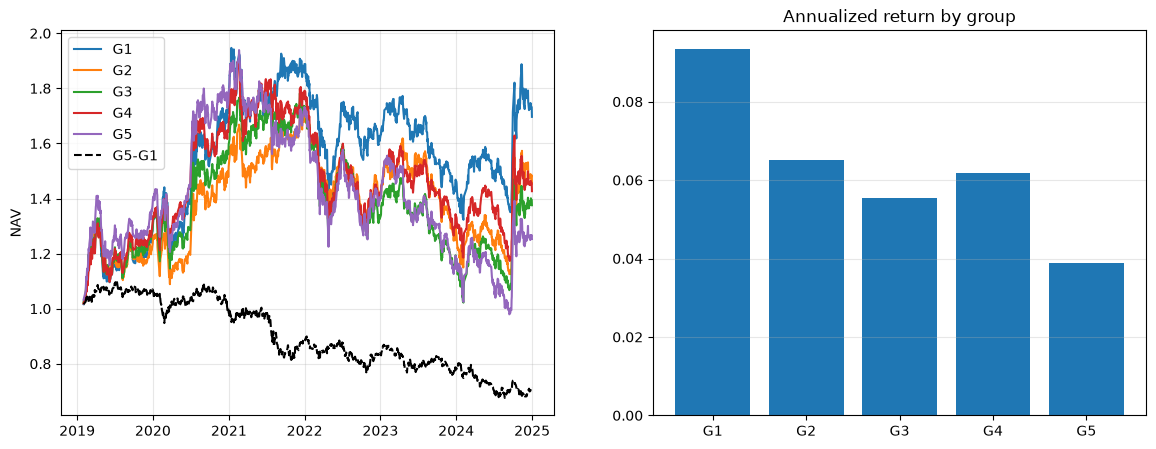

In [83]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

for col in ['G1', 'G2', 'G3', 'G4', 'G5']:
    axes[0].plot(pd.to_datetime(gnav.index), gnav[col], label=col)

axes[0].plot(pd.to_datetime(gnav.index), gnav['G5-G1'], 'k--', label='G5-G1')
axes[0].set_ylabel('NAV')
axes[0].legend()
axes[0].grid(alpha=0.3)

axes[1].bar(['G1', 'G2', 'G3', 'G4', 'G5'], gtable.loc['年化收益', ['G1', 'G2', 'G3', 'G4', 'G5']]) 
                                                    #loc后面分别跟了行名和列名
axes[1].set_title('Annualized return by group')
axes[1].grid(alpha=0.3, axis='y')
plt.show()

In [84]:
ls_m = (1 + group_ret['G5-G1']).groupby(group_ret.index.str[:6]).prod() - 1 #每月收益
    #index.str[:6]：日期字符串取前 6 位，就是年月（比如 '201902'）

t = ls_m.mean() / ls_m.std() * np.sqrt(len(ls_m))

print('月数:', len(ls_m), '月均:', round(ls_m.mean(), 4), 't 值:', round(t, 2))
print('G5-G1 为正的月份比例:', round((ls_m > 0).mean(), 3))

月数: 71 月均: -0.0042 t 值: -1.12
G5-G1 为正的月份比例: 0.479


### 分组回测小结（按综合得分五分组，组内等权，月度调仓，2019-02 至 2024-12）
| | G1(低分) | G2 | G3 | G4 | G5(高分) | G5−G1 |
|---|---|---|---|---|---|---|
| 年化收益 | 9.35% | 6.52% | 5.54% | 6.19% | 3.89% | −5.51% |
| 夏普 | 0.45 | 0.32 | 0.27 | 0.30 | 0.18 | −0.48 |
| 最大回撤 | −32.1% | −34.0% | −42.6% | −38.1% | −49.5% | −38.4% |

- 点估计大体递减（G3/G4 倒挂），但 G5−G1 月度收益 t = −1.12，正收益月份 47.9%，统计上不显著
- 与 IC 结论一致（综合得分 IC 均值 −0.003，t < 1）：打分不具备可靠的选股能力
- t ≈ 夏普 × √年数：夏普 0.48 需约 17 年数据才能达到 t = 2，6 年样本不足以区分信号和噪音
- 各组波动接近（20–22%），收益差异不来自风险差异
- 不因 G5−G1 为负而反转打分方向：看结果改规则属于数据窥探
- 自检：五组平均与股票池等权的最大日差 5.7e-5，来自各组股数不等（N 不能被 5 整除）
- 踩坑：pool 的 trade_date 被读成 int64，reindex 静默匹配失败、fillna(0) 后收益全为 0；应在读取处加 dtype

# 交易成本

## 计算换手率

In [85]:
def calc_turnover(w_rb):                #weight on rebalance date
    """w_rb：调仓日 × 股票 的目标权重矩阵（月度，不是每日）"""
    dw = w_rb.diff()                    # 本期权重 - 上期权重
    dw.iloc[0] = w_rb.iloc[0]-0           # 第一期是从空仓建仓，所以自己手动算
    buy  = dw.clip(lower=0).sum(axis=1)     # .clip(lower=0)，把小于0的数剪掉，只留正数 = 买入比例
    sell = (-dw).clip(lower=0).sum(axis=1)  # 负数取反 = 卖出比例
    return pd.DataFrame({'buy': buy, 'sell': sell, 'turnover': buy + sell})

# 策略：w 就是第 5 节 pivot 出来的 72 × 81 月度权重
to_strat = calc_turnover(w) #to_strat turnover strategy
to_strat.head()



,buy,sell,turnover
trade_date,,,
20190131,1.0,0.0,1.0
20190228,0.1,0.1,0.2
20190329,0.0,0.0,0.0
20190430,0.4,0.4,0.8
20190531,0.4,0.4,0.8


In [86]:
# 股票池等权：之前是链式写法，没有单独存月度矩阵，这里补一个
w_pool_rb = pool_w.pivot_table(index='trade_date', columns='ts_code', values='w', fill_value=0)
to_pool = calc_turnover(w_pool_rb) #turnover pool

print(pool_w.shape)
print(w_pool_rb.shape)
print(to_pool.shape)

print('策略 月均换手:', round(to_strat['turnover'].iloc[1:].mean(), 3)) 
    #算月均时去掉第一期，因为建仓那一期 turnover 必然是 1，不代表日常换手
print('等权 月均换手:', round(to_pool['turnover'].iloc[1:].mean(), 3))
print('策略 平均每月换掉几只:', round((to_strat['sell'].iloc[1:] / 0.1).mean(), 2))

(17622, 3)
(72, 423)
(72, 3)
策略 月均换手: 0.389
等权 月均换手: 0.029
策略 平均每月换掉几只: 1.94


## 扣成本

In [87]:
STAMP_CUT = '20230828'   # 印花税减半的日期

def calc_cost(to, slip=0.001, comm=0.00025): #to turnover, slip滑点/冲击，佣金率
    stamp = np.where(to.index >= STAMP_CUT, 0.0005, 0.001)   # 卖出印花税，8月28号之后是0.05%，之前是0.1%
    cost = to['buy'] * (comm + slip) + to['sell'] * (comm + slip + stamp)
    return pd.Series(cost)

def net_ret(gross, to, **kw):     #**kw
    c = (calc_cost(to, **kw)
         .reindex(price.index).fillna(0)   # 把to扩展成price一样的含有更多交易日的行，调仓日以外的成本为 0
         .shift(1))                        # 成本记到调仓日的下一个交易日
    return gross - c.reindex(gross.index)  # gross 只有 > start 的日期（从 0201 开始），把成本序列裁成同样的日期，两条序列才能逐日对齐

strat_net = net_ret(strategy_ret, to_strat) #踢掉各种交易成本
pool_net  = net_ret(pool_ret, to_pool)

table2 = pd.DataFrame({'策略费前': perf(strategy_ret), '策略费后': perf(strat_net),
                       '等权费前': perf(pool_ret),     '等权费后': perf(pool_net)})
print(table2.round(4))

# 敏感性：滑点是最不确定的假设，换几个值看看
for s in [0, 0.001, 0.002, 0.003]:
    print('单边滑点', s, '策略费后年化', round(perf(net_ret(strategy_ret, to_strat, slip=s))['年化收益'], 4))

        策略费前    策略费后    等权费前    等权费后
年化收益 -0.0022 -0.0101  0.0647  0.0639
年化波动  0.2438  0.2436  0.2007  0.2007
夏普比率 -0.0092 -0.0417  0.3222  0.3183
最大回撤 -0.5374 -0.5497 -0.3769 -0.3780
单边滑点 0 策略费后年化 -0.0054
单边滑点 0.001 策略费后年化 -0.0101
单边滑点 0.002 策略费后年化 -0.0148
单边滑点 0.003 策略费后年化 -0.0195


In [88]:
cost = to_strat['buy'] * 0.00125 + to_strat['sell'] * 0.00225
print(type(cost))
print(cost.index[:3])

<class 'pandas.Series'>
Index(['20190131', '20190228', '20190329'], dtype='str', name='trade_date')


In [89]:
def f(**kw):
    print(kw)

f()
f(slip=0.002)
f(slip=0.002, comm=0.0003)

{}
{'slip': 0.002}
{'slip': 0.002, 'comm': 0.0003}


## 交易成本笔记：换手率与扣费

### 1. 换手率 turnover
- 成本 = 交易金额 × 费率；在权重框架下，交易金额 = 权重变化 Δw = w_t − w_{t−1}
- Δw > 0 为买入，Δw < 0 为卖出
- **双边换手** = buy + sell = Σ|Δw|（我们用这个，因为买卖要分开套费率）
- **单边换手** = 只算 sell，或 (buy+sell)/2；满仓组合除首期外 buy = sell，所以单边 = 双边 / 2
- 说"年换手 X 倍"时必须说明口径；基金年报通常是单边
- 例：10 只等权，换 2 只 → sell 0.2 + buy 0.2 = 双边 0.4
- 结果：策略月均双边 0.389（≈ 每月换 1.94 只，年双边 ≈ 4.7 倍）；股票池等权 0.029
  - 等权不为 0：成分股调整 + N 变化导致所有 1/N 改变
  - 策略换手低：因子来自季报，月间排名变化小

```python
def calc_turnover(w_rb):          # w_rb = weight on rebalance dates，月度权重（不是 w_daily）
    dw = w_rb.diff()
    dw.iloc[0] = w_rb.iloc[0]     # 第一期从空仓建仓
    buy  = dw.clip(lower=0).sum(axis=1)
    sell = (-dw).clip(lower=0).sum(axis=1)
    return pd.DataFrame({'buy': buy, 'sell': sell, 'turnover': buy + sell})
```
- `diff()`：本行减上一行；`clip(lower=0)`：小于 0 的截成 0

### 2. A 股成本假设
| 项目 | 买入 | 卖出 |
|---|---|---|
| 佣金 | 0.025% | 0.025% |
| 印花税 | 0 | 0.1%，2023-08-28 起 0.05% |
| 滑点/冲击 | 0.1% | 0.1%（最不确定 → 做敏感性分析） |

- `np.where(条件, A, B)`：逐个判断，真取 A 假取 B；返回 ndarray，**没有 index**
- **Series 与 ndarray 或数字运算 → 结果仍是 Series，沿用 Series 的 index**
- 坑：`pd.Series(已有Series, index=新index)` 不是贴标签而是 reindex，对不上会静默变成 NaN

### 3. 成本放在哪一天
- `ret = price.pct_change()`：标着 t 的收益 = t 收盘 / t−1 收盘 − 1，即"昨收 → 今收"
- 调仓日收盘交易并付费，这一刻是两个区间的交界 → 成本放进下一个交易日的收益，和 `w_daily.shift(1)` 口径一致
- 净值是连乘的，成本放在交界前一天或后一天，期末净值相同
- shift 的实际作用：① 不丢第一笔建仓成本（gross 从 start 之后开始）② 和持仓口径统一
- **必须先扩到日度再 shift**：在月度表上 shift(1) = 挪一个月，成本全部晚一个月，最后一期丢失，分年度统计会错
- shift(1) 挪的是"一行"，一行多长取决于在哪张表上 shift

```python
def net_ret(gross, to, **kw):
    c = (calc_cost(to, **kw)
         .reindex(price.index).fillna(0)   # 扩到每日，非调仓日为 0
         .shift(1))                        # 落到调仓日下一个交易日
    return gross - c.reindex(gross.index)  # 对齐日期后相减
```
- `**kw`：定义里把多余的带名参数**打包**成字典，调用里再**拆包**转交给 calc_cost；中间人不需要知道参数名
- 近似：真实 (1−c)(1+r) − 1 = r − c − r·c，代码写 r − c；r·c 是"付掉的成本没跟着涨"的部分，例 2% × 0.125% = 0.0025%，可忽略


# 分时间段检验

## 分年度

In [90]:
df = pd.DataFrame({'策略费后': strat_net, '等权费后': pool_net, '沪深300': bench_ret})
df.head()

,策略费后,等权费后,沪深300
trade_date,,,
20190201,0.033302,0.021362,0.014294
20190211,0.026586,0.024296,0.018192
20190212,0.012115,0.014225,0.007217
20190213,0.023042,0.020586,0.020026
20190214,0.012535,0.004044,0.001505


In [91]:
yearly = (1 + df).groupby(df.index.str[:4]).prod() - 1  #str[:4]取年份

yearly['策略-等权'] = yearly['策略费后'] - yearly['等权费后']

print(yearly.round(4))
print('策略跑赢等权的年份:', (yearly['策略-等权'] > 0).sum(), '/', len(yearly))

              策略费后    等权费后   沪深300   策略-等权
trade_date                                
2019        0.1295  0.3038  0.2795 -0.1743
2020        0.3365  0.2800  0.2721  0.0565
2021       -0.0940  0.0627 -0.0520 -0.1567
2022       -0.2408 -0.1914 -0.2163 -0.0495
2023       -0.1371 -0.0936 -0.1138 -0.0434
2024        0.0507  0.1095  0.1468 -0.0588
策略跑赢等权的年份: 1 / 6


## 前后半段

In [92]:
halves = {'2019-2021': ('20190101', '20211231'), '2022-2024': ('20220101', '20241231')}
for name, (a, b) in halves.items(): #name是键值，(a,b)对应的时间前后日期
    print(name)
    print(df.loc[a:b].apply(perf).round(4))

2019-2021
        策略费后    等权费后   沪深300
年化收益  0.1135  0.2174  0.1606
年化波动  0.2298  0.1988  0.2023
夏普比率  0.4938  1.0935  0.7936
最大回撤 -0.3040 -0.1648 -0.1819
2022-2024
        策略费后    等权费后   沪深300
年化收益 -0.1174 -0.0668 -0.0733
年化波动  0.2567  0.2026  0.1842
夏普比率 -0.4574 -0.3299 -0.3978
最大回撤 -0.4661 -0.3555 -0.3576


## IC分年度

In [93]:
ic.head()

,score,eps_ann,roe_ann,debt_to_assets,pb,total_mv
trade_date,,,,,,
20190131,0.031455,-0.242115,-0.107890,-0.117304,0.113817,-0.397137
20190228,0.121670,0.119277,0.109417,-0.073171,0.182408,-0.158292
20190329,0.000053,0.130890,0.063905,0.027849,-0.069900,0.300100
20190430,-0.012138,0.023463,0.033653,-0.045847,0.066189,0.070564
20190531,0.184773,0.319036,0.296969,-0.108459,0.116507,0.227967


In [94]:
ic_year = ic.groupby(ic.index.str[:4]).agg(['mean', 'count'])['score'] 
    #前面已经检验过ic的index是str类型
    #回顾一下：ic的每一列是列名和fwd_ret相关系数的计算
print(ic_year.round(3))

             mean  count
trade_date              
2019        0.033     12
2020       -0.000     12
2021       -0.009     12
2022        0.007     12
2023       -0.030     12
2024       -0.019     11


In [95]:
print(ic.groupby(ic.index.astype(str).str[:4])[['total_mv', 'pb']].mean().round(3))

            total_mv     pb
trade_date                 
2019          -0.001  0.111
2020           0.075  0.139
2021          -0.040 -0.121
2022          -0.003 -0.022
2023           0.069 -0.178
2024          -0.000  0.006


**分时段（费后）**
- 6 年中仅 2020 年跑赢等权；2019–2021 年化 11.35% vs 21.74%，2022–2024 −11.74% vs −6.68%：牛熊市都跑输，问题在选股规则而非市场环境
- 两段波动率都是 23–26%（等权约 20%），回撤更深：10 只集中持仓的风险
- 综合得分年度 IC 在 −0.03 到 0.03 之间，正负各半；年均值标准误 ≈ 0.11/√12 ≈ 0.03，与 0 无法区分
- 市值 IC 正负交替且很小；PB 的 IC 随价值/成长风格整年切换（2019–20 为 +0.11/+0.14，2021 为 −0.12，2023 为 −0.18）：PB 是风格因子，这解释了它 IC 波动最大
- 年度胜负不能完全用因子 IC 解释（如 2020 年），因为策略只持 10 只，个股噪音大
- 分段只用于检验稳健性，不据此挑选时段或调参

- 市值就是最典型的风格因子之一，对应 Fama-French 里的 SMB（小盘减大盘）。A 股说的"大小盘风格切换"，指的就是它。

- 那为什么在你的数据里，它没有 PB 那么明显？


你的年度 IC 里，市值正负交替但都很小（最大 0.075），不像 PB 那样整年大幅偏向一边。原因主要在股票池：

- 你的股票池是沪深 300，本来就是 A 股最大的 300 家公司。池子里"最小的"股票，放到全市场也是大盘股。
- A 股的大小盘风格切换，主要体现在不同指数之间，比如沪深 300 对中证 1000、中证 2000。2021 年和 2023 年小微盘大涨，说的是全市场的小票，不是沪深 300 内部排名靠后的那些。
- 所以在沪深 300 内部，市值差异小，风格效应也被压缩了。